# Seed 44, α=1.0 — Analysis

This notebook follows a **natural flow**:
1. **True score distribution** — Preference dataset and gold (oracle) scores: chosen vs rejected by group (Fig. 2-style).
2. **RM score calibration** — Compare raw vs calibrated vs oracle group rewards; worst-group selection.
3. **PPO policy results** — Load eval datasets (gold, gold_vanilla, vanilla, maxmin), oracle group scores, summary table.

## What changed from seed=43

| Parameter | seed=43 (old) | seed=44 (new) | Effect |
|-----------|--------------|--------------|--------|
| `max_new_tokens` in generation | `max_length=100` (total seq) → ~92 new tokens | `max_new_tokens=200` (new tokens only) | Longer responses; length spread from ≈0 to ≈0.80 |
| Scoring tokenizer `max_length` | 100 | 512 (DistilBERT limit) | No truncation of responses up to 200 tokens |
| Normalization divisor | 100 | **250** | `normalized_length = token_count / 250`; 200-token response → 0.80, not 1.0 |
| Seed | 43 | 44 | Different train/test split for preference data |

**Why this matters for Figure 2:**  
In seed=43, nearly all responses were truncated at 100 tokens → `normalized_length ≈ 1.0` for both chosen and rejected. The minority group score at α=1.0 is `(1 − norm_len) × α`, which collapsed to ≈0 for all responses, giving the minority RM no training signal.  
With the fixes above, `normalized_length` is now spread across roughly `[0.05, 0.80]`, so there is real separation between concise (chosen) and verbose (rejected) responses in the minority group.

## Expected pattern (Fig. 2 in the paper)
- **Minority** (`group_id=0`): separation on **conciseness** (normalized_length), overlap on sentiment
- **Majority** (`group_id=1`): separation on **sentiment** (positiveness), overlap on conciseness

## Pre-alignment preference dataset (Fig. 2)

Below: load preference data and gold scorer, then plot chosen vs rejected score distributions by group.

In [1]:
import math
import numpy as np
import torch
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# ── Config ──────────────────────────────────────────────────────────────────
USER_ID    = "mxcui"
SEED       = 44
PROPORTION = 0.2
ALPHA      = 1.0

DIVISOR         = 250   # new: was 100 in seed=43
SCORER_MAX_LEN  = 512   # new: was 100 in seed=43 (DistilBERT limit)
BATCH_SIZE      = 32
MAX_SAMPLES     = 10000

PREF_DATASET_ID = f"{USER_ID}/gpt2-imdb-seed{SEED}-prop{PROPORTION}-alpha{ALPHA}"
print("Preference dataset:", PREF_DATASET_ID)
print(f"divisor={DIVISOR}  scorer_max_len={SCORER_MAX_LEN}")

Preference dataset: mxcui/gpt2-imdb-seed44-prop0.2-alpha1.0
divisor=250  scorer_max_len=512


In [2]:
# ── Gold scorer (lvwerra/distilbert-imdb) ───────────────────────────────────
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

GOLD_MODEL = "lvwerra/distilbert-imdb"
gold_tok = AutoTokenizer.from_pretrained(GOLD_MODEL)
gold_rm  = AutoModelForSequenceClassification.from_pretrained(GOLD_MODEL).to(device)
gold_rm.eval()
pos_id = gold_rm.config.label2id["POSITIVE"]
print("Loaded gold scorer. pos_id =", pos_id)

device: cuda


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loaded gold scorer. pos_id = 1


In [3]:
# ── Score texts → (positiveness, normalized_length) ────────────────────────
def score_texts(texts, batch_size=BATCH_SIZE):
    """Return positiveness and normalized_length arrays using the updated parameters."""
    pos_all, nlen_all = [], []
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            batch = texts[i : i + batch_size]
            enc = gold_tok(
                batch,
                padding=True,
                truncation=True,
                max_length=SCORER_MAX_LEN,   # 512, not 100
                return_tensors="pt",
            ).to(device)
            out = gold_rm(input_ids=enc["input_ids"],
                          attention_mask=enc["attention_mask"])
            probs = torch.softmax(out.logits, dim=-1)
            pos   = probs[:, pos_id]
            nlen  = torch.clamp(
                enc["attention_mask"].sum(dim=-1).float() / DIVISOR,
                0.0, 1.0
            )
            pos_all.extend(pos.float().cpu().tolist())
            nlen_all.extend(nlen.float().cpu().tolist())
    return np.array(pos_all, dtype=np.float32), np.array(nlen_all, dtype=np.float32)


# ── Load preference dataset ─────────────────────────────────────────────────
pref_ds = load_dataset(PREF_DATASET_ID, split="train")
if MAX_SAMPLES and len(pref_ds) > MAX_SAMPLES:
    pref_ds = pref_ds.shuffle(seed=SEED).select(range(MAX_SAMPLES))
print(f"Loaded {len(pref_ds):,} rows from {PREF_DATASET_ID}")
print("Columns:", pref_ds.column_names)

for col in ("chosen", "rejected", "group_id"):
    if col not in pref_ds.column_names:
        raise RuntimeError(f"Missing column '{col}' — have: {pref_ds.column_names}")

# Collect texts per group and label
by_group = {0: {"chosen": [], "rejected": []},
            1: {"chosen": [], "rejected": []}}
for ex in pref_ds:
    gid = int(ex["group_id"])
    if gid not in by_group:
        continue
    by_group[gid]["chosen"].append(ex["chosen"])
    by_group[gid]["rejected"].append(ex["rejected"])

for gid, gname in [(0, "minority"), (1, "majority")]:
    print(f"  {gname}: {len(by_group[gid]['chosen'])} pairs")

Loaded 10,000 rows from mxcui/gpt2-imdb-seed44-prop0.2-alpha1.0
Columns: ['group_id', 'chosen', 'rejected']
  minority: 2028 pairs
  majority: 7972 pairs


In [21]:
# ── Score all groups ────────────────────────────────────────────────────────
fig2 = {}
for gid, gname in [(0, "minority"), (1, "majority")]:
    print(f"Scoring {gname} ({len(by_group[gid]['chosen'])} pairs)...")
    pos_c, nlen_c = score_texts(by_group[gid]["chosen"])
    pos_r, nlen_r = score_texts(by_group[gid]["rejected"])
    fig2[gname] = {
        "pos_chosen":  pos_c,
        "pos_rejected": pos_r,
        "nlen_chosen": nlen_c,
        "nlen_rejected": nlen_r,
        "n": len(by_group[gid]["chosen"]),
    }

# Quick sanity-check: mean normalized_length
print("\nnormalized_length summary (chosen / rejected):")
for gname in ("minority", "majority"):
    nc = fig2[gname]["nlen_chosen"].mean()
    nr = fig2[gname]["nlen_rejected"].mean()
    pc = fig2[gname]["pos_chosen"].mean()
    pr = fig2[gname]["pos_rejected"].mean()
    print(f"  {gname:8s}  nlen chosen={nc:.3f} {fig2[gname]["nlen_chosen"].std():.3f}"
          f"    rejected={nr:.3f} {fig2[gname]["nlen_rejected"].std():.3f}  "
          f"| pos chosen={pc:.3f} {fig2[gname]["pos_chosen"].std():.3f}"
          f"    rejected={pr:.3f} {fig2[gname]["pos_rejected"].std():.3f}")

Scoring minority (2028 pairs)...
Scoring majority (7972 pairs)...

normalized_length summary (chosen / rejected):
  minority  nlen chosen=0.226 0.171    rejected=0.769 0.189  | pos chosen=0.668 0.419    rejected=0.570 0.445
  majority  nlen chosen=0.476 0.282    rejected=0.527 0.288  | pos chosen=0.923 0.221    rejected=0.241 0.368


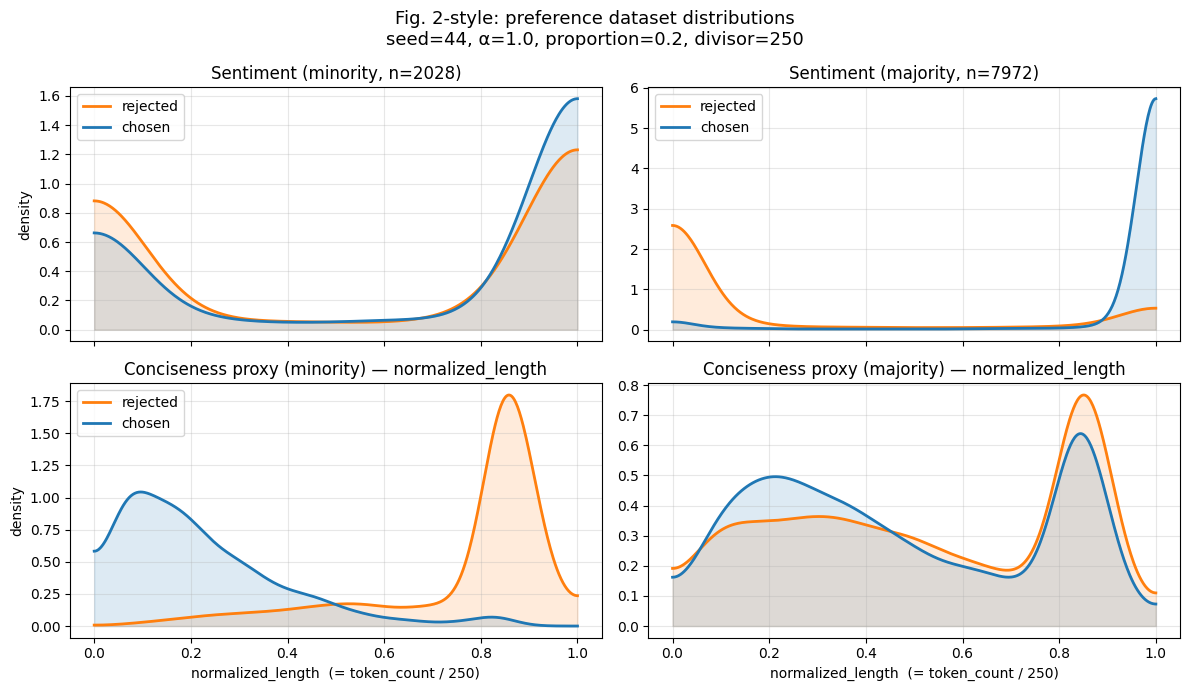

Saved fig2_seed44_alpha1.png


In [5]:
import matplotlib.pyplot as plt

# ── Gaussian KDE with boundary reflection on [0, 1] ────────────────────────
def kde_reflect01(x, grid, bw=None):
    x = np.asarray(x, dtype=np.float64)
    x = x[np.isfinite(x)]
    if x.size == 0:
        return np.zeros_like(grid, dtype=np.float64)
    if bw is None:
        std = np.std(x, ddof=1) if x.size > 1 else 0.1
        bw = float(max(1.06 * std * x.size ** (-0.2), 1e-3))
    xr = np.concatenate([x, -x, 2 - x])   # reflect at 0 and 1
    z  = (grid[:, None] - xr[None, :]) / bw
    return np.exp(-0.5 * z * z).sum(axis=1) / (xr.size * bw * np.sqrt(2 * np.pi))


def plot_kde(ax, x, label, color, bw=None, lw=2, alpha=0.15):
    grid = np.linspace(0, 1, 500)
    dens = kde_reflect01(np.asarray(x), grid, bw=bw)
    ax.plot(grid, dens, color=color, lw=lw, label=label)
    ax.fill_between(grid, 0, dens, color=color, alpha=alpha)


# ── Figure 2-style: chosen vs rejected, by group ────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
fig.suptitle(
    f"Fig. 2-style: preference dataset distributions\n"
    f"seed={SEED}, α={ALPHA}, proportion={PROPORTION}, divisor={DIVISOR}",
    fontsize=13,
)

C_CHOSEN   = "tab:blue"
C_REJECTED = "tab:orange"

# Sentiment — minority
ax = axes[0, 0]
plot_kde(ax, fig2["minority"]["pos_rejected"], "rejected", C_REJECTED)
plot_kde(ax, fig2["minority"]["pos_chosen"],   "chosen",   C_CHOSEN)
ax.set_title(f"Sentiment (minority, n={fig2['minority']['n']})")
ax.set_ylabel("density")
ax.legend(); ax.grid(True, alpha=0.3)

# Sentiment — majority
ax = axes[0, 1]
plot_kde(ax, fig2["majority"]["pos_rejected"], "rejected", C_REJECTED)
plot_kde(ax, fig2["majority"]["pos_chosen"],   "chosen",   C_CHOSEN)
ax.set_title(f"Sentiment (majority, n={fig2['majority']['n']})")
ax.legend(); ax.grid(True, alpha=0.3)

# Conciseness (normalized_length) — minority
ax = axes[1, 0]
plot_kde(ax, fig2["minority"]["nlen_rejected"], "rejected", C_REJECTED)
plot_kde(ax, fig2["minority"]["nlen_chosen"],   "chosen",   C_CHOSEN)
ax.set_title("Conciseness proxy (minority) — normalized_length")
ax.set_xlabel(f"normalized_length  (= token_count / {DIVISOR})")
ax.set_ylabel("density")
ax.legend(); ax.grid(True, alpha=0.3)

# Conciseness (normalized_length) — majority
ax = axes[1, 1]
plot_kde(ax, fig2["majority"]["nlen_rejected"], "rejected", C_REJECTED)
plot_kde(ax, fig2["majority"]["nlen_chosen"],   "chosen",   C_CHOSEN)
ax.set_title("Conciseness proxy (majority) — normalized_length")
ax.set_xlabel(f"normalized_length  (= token_count / {DIVISOR})")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("fig2_seed44_alpha1.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved fig2_seed44_alpha1.png")

---
## RM Scale Analysis & Calibration

Run this section **after** `bash scripts/train_rm_seed44.sh` completes.

### Why calibration matters
MaxMin PPO selects the "worst" group by comparing **mean reward** across two separately trained reward models.  
Because the two RMs are trained independently, their raw logit scales can differ — e.g. one RM outputs logits in [−3, 1] while the other outputs [0, 4]. MaxMin will then always pick the same group as "worst" regardless of the policy's actual performance.

**Calibration** fits a per-group sigmoid affine transform `sigmoid(a·r + b) ≈ gold(x) ∈ [0,1]` so that both RMs are mapped to the same interpretable scale before comparison.

### Cells below
1. Load the two MaxMin RMs from Hub  
2. Score preference dataset texts → collect raw logits  
3. Load calibration JSON (written by `train_rm_seed44.sh` step 4) → apply transform  
4. Plot raw vs calibrated vs oracle distributions  
5. Simulate batch-level worst-group selection: raw vs calibrated vs oracle

In [6]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer

# ── Load trained MaxMin RMs ─────────────────────────────────────────────────
RM_MAX_LEN = 256  # GPT2 tokenizer; keep consistent with reward training
RM_MIN_ID  = f"{USER_ID}/maxmin-imdb-reward-prop{PROPORTION}-alpha{ALPHA}-seed{SEED}-minority"
RM_MAJ_ID  = f"{USER_ID}/maxmin-imdb-reward-prop{PROPORTION}-alpha{ALPHA}-seed{SEED}-majority"

print("Loading:", RM_MIN_ID)
rm_min = AutoModelForSequenceClassification.from_pretrained(RM_MIN_ID).to(device)
rm_min.eval()

print("Loading:", RM_MAJ_ID)
rm_maj = AutoModelForSequenceClassification.from_pretrained(RM_MAJ_ID).to(device)
rm_maj.eval()

rm_tok = AutoTokenizer.from_pretrained(RM_MAJ_ID)
if rm_tok.pad_token is None:
    rm_tok.pad_token = rm_tok.eos_token

print("Done.")

Loading: mxcui/maxmin-imdb-reward-prop0.2-alpha1.0-seed44-minority


Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

Loading: mxcui/maxmin-imdb-reward-prop0.2-alpha1.0-seed44-majority


Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

Done.


In [7]:
SCORE_MAX = 1000  # texts per group for analysis (cap to keep it fast)

def rm_logits(texts, model, batch_size=BATCH_SIZE):
    """Score texts with a reward model; return raw logits as np array."""
    out_all = []
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            batch = texts[i : i + batch_size]
            enc = rm_tok(
                batch, padding=True, truncation=True,
                max_length=RM_MAX_LEN, return_tensors="pt",
            ).to(device)
            logit = model(**enc).logits.squeeze(-1)
            out_all.extend(logit.float().cpu().tolist())
    return np.array(out_all, dtype=np.float32)


def oracle_group_score(texts, group_id, batch_size=BATCH_SIZE):
    """Compute oracle group score for a list of texts using the gold scorer."""
    pos_all, nlen_all = score_texts(texts, batch_size=batch_size)
    a = ALPHA
    if group_id == 0:  # minority: conciseness
        return (1 - nlen_all) * a + (1 - a) * pos_all
    else:              # majority: positiveness
        return (1 - nlen_all) * (1 - a) + a * pos_all


# ── Balanced text sample: equal chosen and rejected per group ────────────────
# This avoids the [:SCORE_MAX] truncation accidentally selecting only chosen texts.
# We interleave chosen and rejected so the mix is representative of what the RM
# will see during PPO (a mix of good and bad responses from the policy).
def balanced_sample(chosen_list, rejected_list, n_each):
    rng_local = np.random.default_rng(SEED)
    idx_c = rng_local.choice(len(chosen_list),  size=min(n_each, len(chosen_list)),  replace=False)
    idx_r = rng_local.choice(len(rejected_list), size=min(n_each, len(rejected_list)), replace=False)
    return ([chosen_list[i] for i in idx_c] + [rejected_list[i] for i in idx_r])

min_texts = balanced_sample(by_group[0]["chosen"], by_group[0]["rejected"], SCORE_MAX)
maj_texts = balanced_sample(by_group[1]["chosen"], by_group[1]["rejected"], SCORE_MAX)

print(f"Scoring {len(min_texts)} minority texts ({SCORE_MAX} chosen + {len(min_texts)-SCORE_MAX} rejected)")
print(f"Scoring {len(maj_texts)} majority texts ({SCORE_MAX} chosen + {len(maj_texts)-SCORE_MAX} rejected)")

# Raw logits from each group's own RM
min_raw = rm_logits(min_texts, rm_min)
maj_raw = rm_logits(maj_texts, rm_maj)

# Oracle gold scores for each group
min_oracle = oracle_group_score(min_texts, group_id=0)
maj_oracle = oracle_group_score(maj_texts, group_id=1)

print("\n── Raw RM logit statistics ─────────────────────────────────────")
print(f"  minority RM on minority texts: mean={min_raw.mean():.4f}  std={min_raw.std():.4f}"
      f"  min={min_raw.min():.3f}  max={min_raw.max():.3f}")
print(f"  majority RM on majority texts: mean={maj_raw.mean():.4f}  std={maj_raw.std():.4f}"
      f"  min={maj_raw.min():.3f}  max={maj_raw.max():.3f}")

print("\n── Oracle gold score statistics ────────────────────────────────")
print(f"  minority oracle: mean={min_oracle.mean():.4f}  std={min_oracle.std():.4f}")
print(f"  majority oracle: mean={maj_oracle.mean():.4f}  std={maj_oracle.std():.4f}")

print("\n─── Scale gap (raw) ─────────────────────────────────────────────")
print(f"  Δmean = minority_raw_mean - majority_raw_mean = "
      f"{min_raw.mean() - maj_raw.mean():.4f}")
print("  If |Δmean| is large, MaxMin will always pick the same group (scale mismatch).")

Scoring 2000 minority texts (1000 chosen + 1000 rejected)
Scoring 2000 majority texts (1000 chosen + 1000 rejected)

── Raw RM logit statistics ─────────────────────────────────────
  minority RM on minority texts: mean=1.1762  std=1.9625  min=-3.967  max=3.676
  majority RM on majority texts: mean=0.2208  std=1.2615  min=-3.316  max=4.939

── Oracle gold score statistics ────────────────────────────────
  minority oracle: mean=0.5056  std=0.3293
  majority oracle: mean=0.5788  std=0.4590

─── Scale gap (raw) ─────────────────────────────────────────────
  Δmean = minority_raw_mean - majority_raw_mean = 0.9554
  If |Δmean| is large, MaxMin will always pick the same group (scale mismatch).


In [8]:
import json, os

# ── Load calibration JSON ────────────────────────────────────────────────────
CALIB_JSON = os.path.join(
    os.path.dirname(os.getcwd()),  # repo root (notebook is in notebooks/)
    f"calibration/calibration_seed{SEED}_alpha{ALPHA}.json"
)
# Fallback: look relative to notebook dir
if not os.path.exists(CALIB_JSON):
    CALIB_JSON = os.path.join(
        os.getcwd(), "..",
        f"calibration/calibration_seed{SEED}_alpha{ALPHA}.json"
    )

print("Loading calibration from:", CALIB_JSON)
with open(CALIB_JSON) as f:
    calib = json.load(f)

a_min = calib["groups"]["minority"]["a"]
b_min = calib["groups"]["minority"]["b"]
a_maj = calib["groups"]["majority"]["a"]
b_maj = calib["groups"]["majority"]["b"]

print(f"\nFitted calibration parameters:")
print(f"  minority: a={a_min:.6f},  b={b_min:.6f},  mse={calib['groups']['minority']['mse']:.6f}")
print(f"  majority: a={a_maj:.6f},  b={b_maj:.6f},  mse={calib['groups']['majority']['mse']:.6f}")

# ── Apply calibration ────────────────────────────────────────────────────────
def sigmoid(x): return 1.0 / (1.0 + np.exp(-np.clip(x, -30, 30)))

min_cal = sigmoid(a_min * min_raw + b_min)
maj_cal = sigmoid(a_maj * maj_raw + b_maj)

print(f"\nCalibrated score statistics:")
print(f"  minority calibrated: mean={min_cal.mean():.4f}  std={min_cal.std():.4f}")
print(f"  majority calibrated: mean={maj_cal.mean():.4f}  std={maj_cal.std():.4f}")
print(f"\n  Δmean calibrated = minority_cal_mean - majority_cal_mean = "
      f"{min_cal.mean() - maj_cal.mean():.4f}")

print(f"\nOracle reference:")
print(f"  Δmean oracle = minority_oracle_mean - majority_oracle_mean = "
      f"{min_oracle.mean() - maj_oracle.mean():.4f}")

Loading calibration from: /home/mx/fairness-rlhf/calibration/calibration_seed44_alpha1.0.json

Fitted calibration parameters:
  minority: a=0.993119,  b=-1.643410,  mse=0.081368
  majority: a=2.050855,  b=0.238028,  mse=0.092050

Calibrated score statistics:
  minority calibrated: mean=0.4797  std=0.3028
  majority calibrated: mean=0.5813  std=0.3670

  Δmean calibrated = minority_cal_mean - majority_cal_mean = -0.1016

Oracle reference:
  Δmean oracle = minority_oracle_mean - majority_oracle_mean = -0.0732


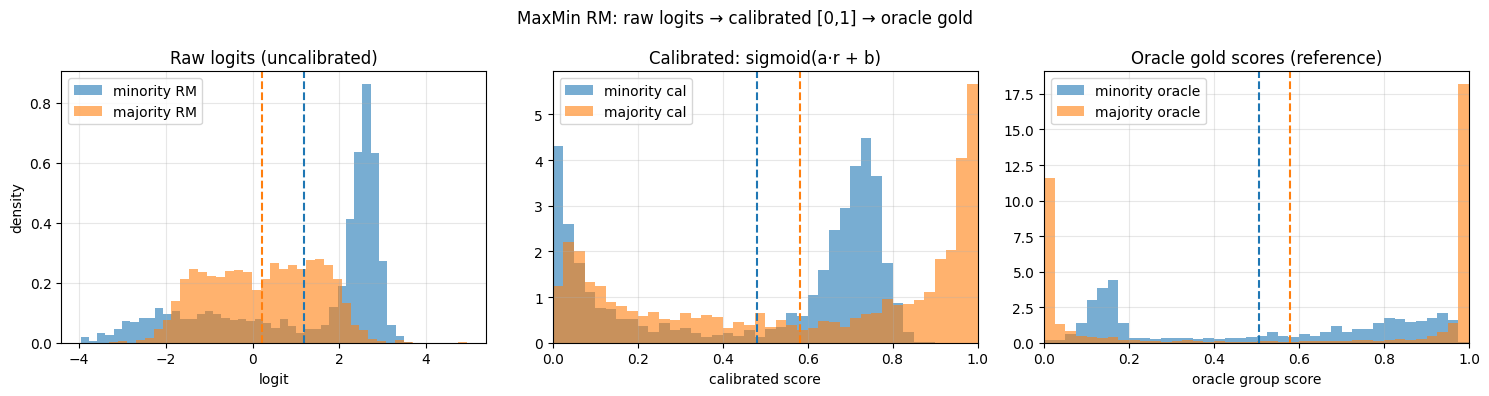

Saved rm_scale_seed44.png

Dashed lines = group means. Compare panel 1 vs panel 2 vs panel 3:
  If panel-1 means are ordered differently from panel-3 → calibration matters.


In [9]:
import matplotlib.pyplot as plt

# ── 3-panel distribution plot: raw → calibrated → oracle ────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle(
    "MaxMin RM: raw logits → calibrated [0,1] → oracle gold",
    fontsize=12,
)

C_MIN = "tab:blue"
C_MAJ = "tab:orange"

# Panel 1: raw logits (different axes!)
ax = axes[0]
ax.hist(min_raw, bins=40, density=True, alpha=0.6, color=C_MIN, label="minority RM")
ax.hist(maj_raw, bins=40, density=True, alpha=0.6, color=C_MAJ, label="majority RM")
ax.set_title("Raw logits (uncalibrated)")
ax.set_xlabel("logit")
ax.set_ylabel("density")
ax.legend()
ax.grid(True, alpha=0.3)
ax.axvline(min_raw.mean(), color=C_MIN, ls="--", lw=1.5)
ax.axvline(maj_raw.mean(), color=C_MAJ, ls="--", lw=1.5)

# Panel 2: calibrated scores (shared [0,1] axis)
ax = axes[1]
bins01 = np.linspace(0, 1, 41)
ax.hist(min_cal, bins=bins01, density=True, alpha=0.6, color=C_MIN, label="minority cal")
ax.hist(maj_cal, bins=bins01, density=True, alpha=0.6, color=C_MAJ, label="majority cal")
ax.set_title("Calibrated: sigmoid(a·r + b)")
ax.set_xlabel("calibrated score")
ax.set_xlim(0, 1)
ax.legend()
ax.grid(True, alpha=0.3)
ax.axvline(min_cal.mean(), color=C_MIN, ls="--", lw=1.5)
ax.axvline(maj_cal.mean(), color=C_MAJ, ls="--", lw=1.5)

# Panel 3: oracle gold scores (reference)
ax = axes[2]
ax.hist(min_oracle, bins=bins01, density=True, alpha=0.6, color=C_MIN, label="minority oracle")
ax.hist(maj_oracle, bins=bins01, density=True, alpha=0.6, color=C_MAJ, label="majority oracle")
ax.set_title("Oracle gold scores (reference)")
ax.set_xlabel("oracle group score")
ax.set_xlim(0, 1)
ax.legend()
ax.grid(True, alpha=0.3)
ax.axvline(min_oracle.mean(), color=C_MIN, ls="--", lw=1.5)
ax.axvline(maj_oracle.mean(), color=C_MAJ, ls="--", lw=1.5)

plt.tight_layout()
plt.savefig("rm_scale_seed44.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved rm_scale_seed44.png")
print("\nDashed lines = group means. Compare panel 1 vs panel 2 vs panel 3:")
print("  If panel-1 means are ordered differently from panel-3 → calibration matters.")

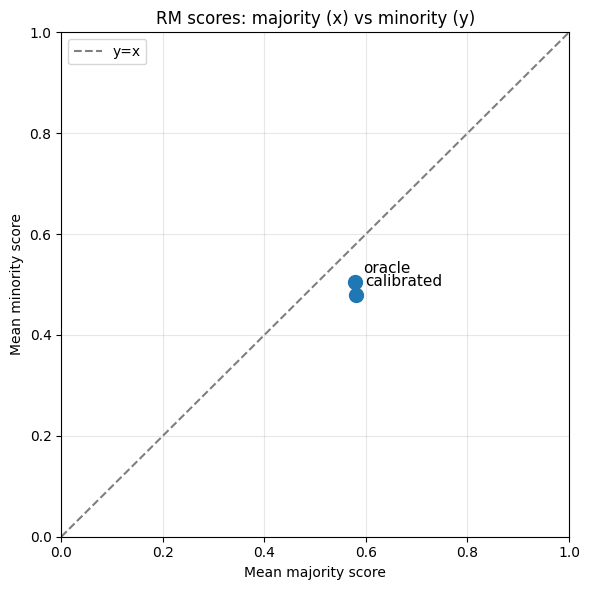

In [18]:
# Scatter: x = mean majority score, y = mean minority score (raw / calibrated / oracle)
import matplotlib.pyplot as plt
import numpy as np

# Use data from the 3-panel cell: one point per score type
points = [
    (np.mean(maj_raw), np.mean(min_raw), "raw"),
    (np.mean(maj_cal), np.mean(min_cal), "calibrated"),
    (np.mean(maj_oracle), np.mean(min_oracle), "oracle"),
]
x_maj = [p[0] for p in points]
y_min = [p[1] for p in points]
labels = [p[2] for p in points]

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(x_maj, y_min, s=100)
for i, lab in enumerate(labels):
    ax.annotate(lab, (x_maj[i], y_min[i]), xytext=(6, 6), textcoords="offset points", fontsize=11)
ax.set_xlabel("Mean majority score")
ax.set_ylabel("Mean minority score")
ax.set_title("RM scores: majority (x) vs minority (y)")
ax.plot([0, 1], [0, 1], "k--", alpha=0.5, label="y=x")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [10]:
import random

# ── Batch-level worst-group selection simulation ─────────────────────────────
# Mimics PPO Algorithm 1: for each batch, compute mean reward per group,
# pick argmin (the group with the lowest mean reward).

SIM_BATCH_SIZE  = 32   # same as PPO batch / num_groups
N_SIM_BATCHES   = 300  # number of simulated batches
rng = random.Random(SEED)

# We have (min_raw, min_cal, min_oracle) for minority texts
# and (maj_raw, maj_cal, maj_oracle) for majority texts
# Sample equal-sized sub-batches from each group, compute group means, pick worst.

n_min = len(min_raw)
n_maj = len(maj_raw)

counts_raw    = {"minority": 0, "majority": 0}
counts_cal    = {"minority": 0, "majority": 0}
counts_oracle = {"minority": 0, "majority": 0}

for _ in range(N_SIM_BATCHES):
    # sample indices (with replacement to allow more batches than data)
    idx_min = [rng.randrange(n_min) for _ in range(SIM_BATCH_SIZE)]
    idx_maj = [rng.randrange(n_maj) for _ in range(SIM_BATCH_SIZE)]

    # raw: compare raw logit means
    mean_min_raw = min_raw[idx_min].mean()
    mean_maj_raw = maj_raw[idx_maj].mean()
    worst_raw = "minority" if mean_min_raw < mean_maj_raw else "majority"
    counts_raw[worst_raw] += 1

    # calibrated: compare calibrated score means
    mean_min_cal = min_cal[idx_min].mean()
    mean_maj_cal = maj_cal[idx_maj].mean()
    worst_cal = "minority" if mean_min_cal < mean_maj_cal else "majority"
    counts_cal[worst_cal] += 1

    # oracle: compare gold score means
    mean_min_ora = min_oracle[idx_min].mean()
    mean_maj_ora = maj_oracle[idx_maj].mean()
    worst_ora = "minority" if mean_min_ora < mean_maj_ora else "majority"
    counts_oracle[worst_ora] += 1

total = N_SIM_BATCHES
print(f"Worst-group selection over {total} simulated batches (batch_size={SIM_BATCH_SIZE}):")
print()
print(f"{'Method':20s}  {'minority':>10s}  {'majority':>10s}")
print("-" * 45)
for label, counts in [("raw (uncalibrated)", counts_raw),
                       ("calibrated",         counts_cal),
                       ("oracle (reference)", counts_oracle)]:
    pmin = 100 * counts["minority"] / total
    pmaj = 100 * counts["majority"] / total
    print(f"{label:20s}  {pmin:9.1f}%  {pmaj:9.1f}%")

print()
print("Interpretation:")
print("  If 'raw' is heavily biased (>90% one group) but 'oracle' is balanced,")
print("  calibration is essential. Check if 'calibrated' better matches 'oracle'.")

Worst-group selection over 300 simulated batches (batch_size=32):

Method                  minority    majority
---------------------------------------------
raw (uncalibrated)          0.0%      100.0%
calibrated                 94.0%        6.0%
oracle (reference)         76.3%       23.7%

Interpretation:
  If 'raw' is heavily biased (>90% one group) but 'oracle' is balanced,
  calibration is essential. Check if 'calibrated' better matches 'oracle'.


## Evaluation results (PPO eval datasets)

Load seed=44, alpha=1.0 PPO eval datasets from the Hub; recompute oracle group scores (minority/majority) from positiveness and normalized_length; print per-method summary table. Same structure as the first part of analyze_seed43_alpha1.ipynb.

In [11]:
import math
from collections import defaultdict
from datasets import load_dataset

USER_ID = "mxcui"
SEED = 44
PROPORTION = 0.2
ALPHA = 1.0
METHODS = {"gold": "gold", "gold_vanilla": "gold-vanilla", "vanilla": "vanilla", "maxmin": "maxmin"}
METHOD_ORDER = ["gold", "gold_vanilla", "vanilla", "maxmin"]

def _pick_first_split(loaded):
    if hasattr(loaded, "keys"):
        keys = list(loaded.keys())
        if not keys:
            raise ValueError("Loaded DatasetDict has no splits")
        return loaded[keys[0]]
    return loaded

def eval_dataset_id(method_key: str) -> str:
    prefix = METHODS[method_key]
    if method_key == "gold":
        return f"{USER_ID}/{prefix}-imdb-ppo-eval-alpha{ALPHA}-seed{SEED}"
    return f"{USER_ID}/{prefix}-imdb-ppo-eval-prop{PROPORTION}-alpha{ALPHA}-seed{SEED}"

def to_float(x, default=math.nan):
    if x is None:
        return default
    try:
        return float(x)
    except Exception:
        return default

def mean(xs):
    xs = [x for x in xs if x is not None and not (isinstance(x, float) and math.isnan(x))]
    return sum(xs) / len(xs) if xs else math.nan

def std(xs):
    xs = [x for x in xs if x is not None and not (isinstance(x, float) and math.isnan(x))]
    if len(xs) < 2:
        return math.nan
    m = sum(xs) / len(xs)
    return math.sqrt(sum((x - m) ** 2 for x in xs) / (len(xs) - 1))

def oracle_scores(positiveness: float, normalized_length: float, alpha: float):
    min_s = (1.0 - normalized_length) * alpha + (1.0 - alpha) * positiveness
    maj_s = (1.0 - normalized_length) * (1.0 - alpha) + alpha * positiveness
    return min_s, maj_s

In [12]:
# Load eval datasets and build combined list of rows
combined = []
failed = []

for method_key in METHOD_ORDER:
    ds_id = eval_dataset_id(method_key)
    print(f"Loading {method_key}: {ds_id}")
    try:
        loaded = load_dataset(ds_id)
        ds = _pick_first_split(loaded)
    except Exception as e:
        failed.append((method_key, ds_id, str(e)))
        continue
    needed = ["prompt", "completion", "positiveness", "length", "normalized_length"]
    missing = [c for c in needed if c not in ds.column_names]
    if missing:
        print(f"  Missing columns: {missing}")
    for ex in ds:
        row = {
            "method": method_key,
            "prompt": ex.get("prompt"),
            "completion": ex.get("completion"),
            "positiveness": to_float(ex.get("positiveness")),
            "length": to_float(ex.get("length")),
            "normalized_length": to_float(ex.get("normalized_length")),
        }
        min_s, maj_s = oracle_scores(row["positiveness"], row["normalized_length"], ALPHA)
        row["minority_score"] = min_s
        row["majority_score"] = maj_s
        row["group_gap"] = maj_s - min_s
        combined.append(row)
    print(f"  loaded {len(ds):,} rows")

print(f"\nCombined rows: {len(combined):,}")
if failed:
    print("\nFailed loads:")
    for m, did, err in failed:
        print(f"- {m}: {did}\n  {err}\n")

Loading gold: mxcui/gold-imdb-ppo-eval-alpha1.0-seed44
Loading gold_vanilla: mxcui/gold-vanilla-imdb-ppo-eval-prop0.2-alpha1.0-seed44
Loading vanilla: mxcui/vanilla-imdb-ppo-eval-prop0.2-alpha1.0-seed44


README.md:   0%|          | 0.00/439 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/1.77M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/24872 [00:00<?, ? examples/s]

  loaded 24,872 rows
Loading maxmin: mxcui/maxmin-imdb-ppo-eval-prop0.2-alpha1.0-seed44


README.md:   0%|          | 0.00/439 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/1.73M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/24872 [00:00<?, ? examples/s]

  loaded 24,872 rows

Combined rows: 49,744

Failed loads:
- gold: mxcui/gold-imdb-ppo-eval-alpha1.0-seed44
  Dataset 'mxcui/gold-imdb-ppo-eval-alpha1.0-seed44' doesn't exist on the Hub or cannot be accessed.

- gold_vanilla: mxcui/gold-vanilla-imdb-ppo-eval-prop0.2-alpha1.0-seed44
  Dataset 'mxcui/gold-vanilla-imdb-ppo-eval-prop0.2-alpha1.0-seed44' doesn't exist on the Hub or cannot be accessed.



In [13]:
# Summary table: mean ± std by method
metrics = [
    ("positiveness", "pos"),
    ("length", "len"),
    ("normalized_length", "norm_len"),
    ("minority_score", "minority_score"),
    ("majority_score", "majority_score"),
    ("group_gap", "gap(maj-min)"),
]
by_method = defaultdict(list)
for r in combined:
    by_method[r["method"]].append(r)
rows = []
for method_key in METHOD_ORDER:
    rs = by_method.get(method_key, [])
    if not rs:
        continue
    out = {"method": method_key, "n": len(rs)}
    for k, label in metrics:
        xs = [to_float(r.get(k)) for r in rs]
        out[label] = (mean(xs), std(xs))
    rows.append(out)

def fmt(m_s):
    m, s = m_s
    if math.isnan(m):
        return "nan"
    if math.isnan(s):
        return f"{m:.4f}"
    return f"{m:.4f} ± {s:.4f}"

col_headers = ["method", "n"] + [label for _, label in metrics]
col_width = {h: len(h) for h in col_headers}
for r in rows:
    col_width["method"] = max(col_width["method"], len(str(r["method"])))
    col_width["n"] = max(col_width["n"], len(str(r["n"])))
    for _, label in metrics:
        col_width[label] = max(col_width[label], len(fmt(r[label])))
line = " | ".join(h.ljust(col_width[h]) for h in col_headers)
sep = "-+-".join("-" * col_width[h] for h in col_headers)
print(line)
print(sep)
for r in rows:
    parts = [str(r["method"]).ljust(col_width["method"]), str(r["n"]).rjust(col_width["n"])]
    for _, label in metrics:
        parts.append(fmt(r[label]).rjust(col_width[label]))
    print(" | ".join(parts))

method  | n     | pos             | len               | norm_len        | minority_score  | majority_score  | gap(maj-min)    
--------+-------+-----------------+-------------------+-----------------+-----------------+-----------------+-----------------
vanilla | 24872 | 0.9350 ± 0.2028 | 21.3975 ± 10.7756 | 0.0856 ± 0.0431 | 0.9144 ± 0.0431 | 0.9350 ± 0.2028 |  0.0206 ± 0.2118
maxmin  | 24872 | 0.8851 ± 0.2655 | 20.2156 ± 10.4181 | 0.0809 ± 0.0417 | 0.9191 ± 0.0417 | 0.8851 ± 0.2655 | -0.0340 ± 0.2725


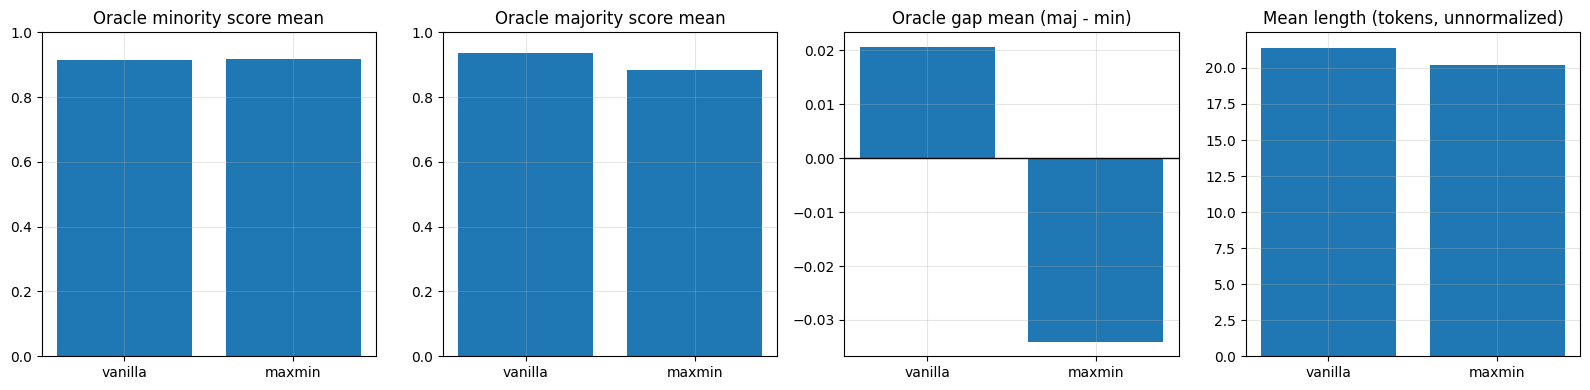

In [14]:
# Optional bar charts (score comparison + unnormalized length by method)
try:
    import matplotlib.pyplot as plt
except Exception as e:
    print("matplotlib not available:", e)
    plt = None

if plt is not None and rows:
    labels = [r["method"] for r in rows]
    def get_means(field_label):
        return [r[field_label][0] for r in rows]
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    axes[0].bar(labels, get_means("minority_score"))
    axes[0].set_title("Oracle minority score mean")
    axes[0].set_ylim(0, 1)
    axes[0].grid(True, alpha=0.3)
    axes[1].bar(labels, get_means("majority_score"))
    axes[1].set_title("Oracle majority score mean")
    axes[1].set_ylim(0, 1)
    axes[1].grid(True, alpha=0.3)
    axes[2].bar(labels, get_means("gap(maj-min)"))
    axes[2].set_title("Oracle gap mean (maj - min)")
    axes[2].axhline(0, color="black", linewidth=1)
    axes[2].grid(True, alpha=0.3)
    axes[3].bar(labels, get_means("len"))
    axes[3].set_title("Mean length (tokens, unnormalized)")
    axes[3].grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

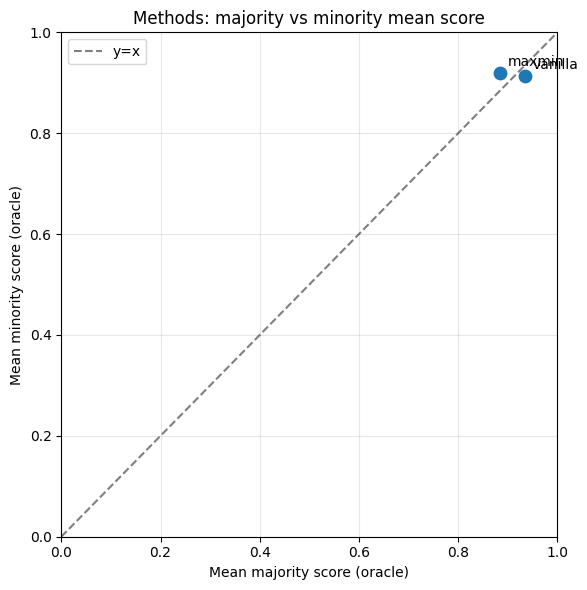

In [17]:
# Scatter: mean majority score (x) vs mean minority score (y) per method
import matplotlib.pyplot as plt

if 'rows' in dir() and rows:
    labels = [r["method"] for r in rows]
    x_maj = [r["majority_score"][0] for r in rows]
    y_min = [r["minority_score"][0] for r in rows]
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(x_maj, y_min, s=80)
    for i, lab in enumerate(labels):
        ax.annotate(lab, (x_maj[i], y_min[i]), xytext=(5, 5), textcoords="offset points", fontsize=10)
    ax.set_xlabel("Mean majority score (oracle)")
    ax.set_ylabel("Mean minority score (oracle)")
    ax.set_title("Methods: majority vs minority mean score")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.plot([0, 1], [0, 1], "k--", alpha=0.5, label="y=x")
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

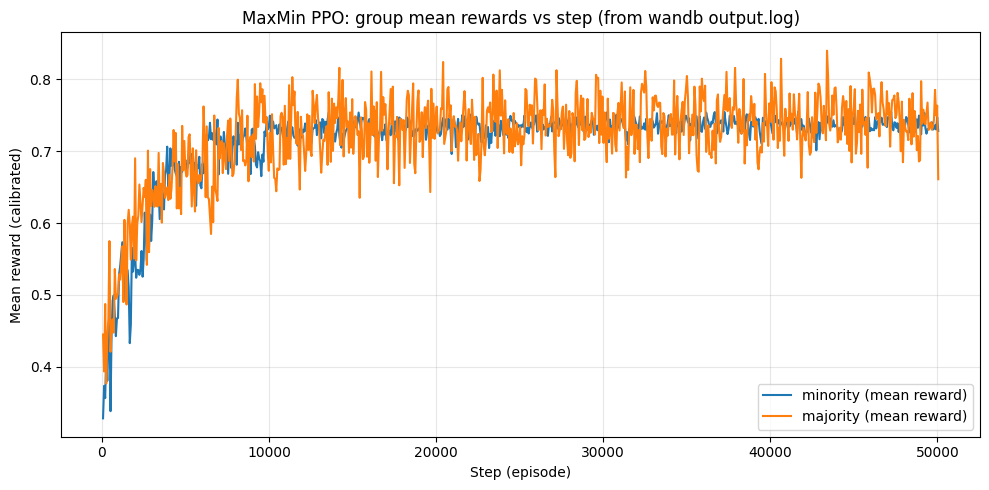

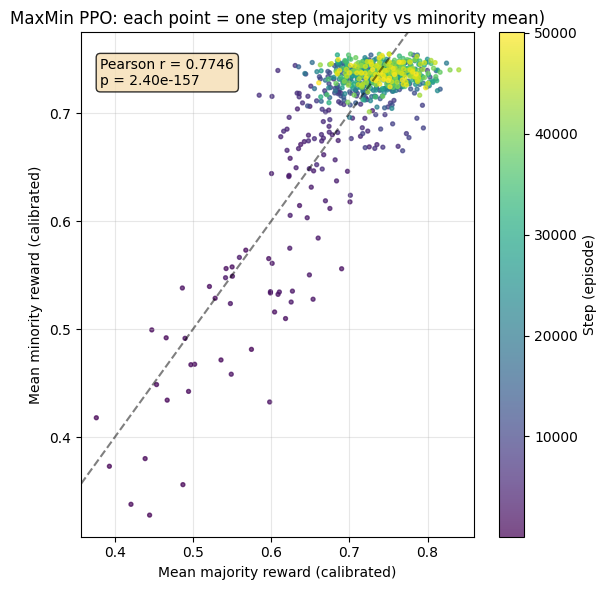

In [20]:
# Plot group mean rewards vs step from the same wandb run output.log
import re
from pathlib import Path
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# Resolve project root (same logic as previous cell)
def _find_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "src" / "imdb").exists() and (p / "notebooks").exists():
            return p
    return start
project_root = _find_root(Path.cwd())
wandb_dir = project_root / "wandb"
maxmin_model_id = f"{USER_ID}/maxmin-imdb-ppo-prop{PROPORTION}-alpha{ALPHA}-seed{SEED}"
candidates = []
for cfg in wandb_dir.glob("run-*/files/config.yaml"):
    try:
        if maxmin_model_id in cfg.read_text(errors="ignore"):
            candidates.append(cfg)
    except Exception:
        continue
if not candidates:
    print("No matching wandb run; skip plot.")
else:
    candidates.sort(key=lambda p: p.stat().st_mtime, reverse=True)
    run_dir = candidates[0].parents[1]
    log_path = run_dir / "files" / "output.log"
    if not log_path.exists():
        print("output.log not found; skip plot.")
    else:
        text = log_path.read_text(errors="ignore")
        # Parse each log line that looks like a dict: episode, mean_reward_minority, mean_reward_majority
        episode_pat = re.compile(r"'episode':\s*(\d+)")
        epoch_pat = re.compile(r"'epoch':\s*'([^']+)'")
        mean_min_pat = re.compile(r"'group_selection/mean_reward_minority':\s*'([^']+)'")
        mean_maj_pat = re.compile(r"'group_selection/mean_reward_majority':\s*'([^']+)'")
        steps, epochs, mean_min, mean_maj = [], [], [], []
        for line in text.split("\n"):
            if "group_selection/mean_reward_minority" not in line:
                continue
            ep = episode_pat.search(line)
            epo = epoch_pat.search(line)
            mmin = mean_min_pat.search(line)
            mmaj = mean_maj_pat.search(line)
            if ep and mmin and mmaj:
                steps.append(int(ep.group(1)))
                mean_min.append(float(mmin.group(1)))
                mean_maj.append(float(mmaj.group(1)))
                if epo:
                    try:
                        epochs.append(float(epo.group(1)))
                    except ValueError:
                        epochs.append(len(steps) - 1)
        if steps:
            fig, ax = plt.subplots(figsize=(10, 5))
            ax.plot(steps, mean_min, label="minority (mean reward)", color="C0")
            ax.plot(steps, mean_maj, label="majority (mean reward)", color="C1")
            ax.set_xlabel("Step (episode)")
            ax.set_ylabel("Mean reward (calibrated)")
            ax.set_title("MaxMin PPO: group mean rewards vs step (from wandb output.log)")
            ax.legend()
            ax.grid(True, alpha=0.3)
            plt.tight_layout()
            plt.show()
            # Scatter: x = majority mean, y = minority mean (one point per training step)
            r_pearson, p_pearson = pearsonr(mean_maj, mean_min)
            fig2, ax2 = plt.subplots(figsize=(6, 6))
            sc = ax2.scatter(mean_maj, mean_min, c=steps, cmap="viridis", s=8, alpha=0.7)
            ax2.set_xlabel("Mean majority reward (calibrated)")
            ax2.set_ylabel("Mean minority reward (calibrated)")
            ax2.set_title("MaxMin PPO: each point = one step (majority vs minority mean)")
            ax2.text(0.05, 0.95, f"Pearson r = {r_pearson:.4f}\np = {p_pearson:.2e}", transform=ax2.transAxes, fontsize=10, verticalalignment="top", bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.8))
            ax2.plot([0, 1], [0, 1], "k--", alpha=0.5, label="y=x")
            ax2.set_xlim(min(mean_maj)-0.02, max(mean_maj)+0.02)
            ax2.set_ylim(min(mean_min)-0.02, max(mean_min)+0.02)
            ax2.grid(True, alpha=0.3)
            plt.colorbar(sc, ax=ax2, label="Step (episode)")
            plt.tight_layout()
            plt.show()
        else:
            print("No group_selection/mean_reward lines found in output.log")

In [16]:
import re
from collections import Counter
from pathlib import Path


def find_project_root(start: Path) -> Path:
    """Walk up from start until we find a dir containing both 'src/imdb' and 'notebooks'."""
    for parent in [start, *start.parents]:
        if (parent / "src" / "imdb").exists() and (parent / "notebooks").exists():
            return parent
    raise FileNotFoundError(f"Project root not found from {start}")

maxmin_model_id = f"{USER_ID}/maxmin-imdb-ppo-prop{PROPORTION}-alpha{ALPHA}-seed{SEED}"
print("Target maxmin PPO model id:", maxmin_model_id)

project_root = find_project_root(Path.cwd())
wandb_dir = project_root / "wandb"
if not wandb_dir.exists():
    raise RuntimeError(f"No wandb directory found at: {wandb_dir}")

# Find candidate runs by scanning config.yaml for the model id
candidates = []
for cfg in wandb_dir.glob("run-*/files/config.yaml"):
    try:
        txt = cfg.read_text(errors="ignore")
    except Exception:
        continue
    if maxmin_model_id in txt:
        candidates.append(cfg)

print(f"Found {len(candidates)} wandb run(s) matching model id")
for c in candidates[:5]:
    print("-", c)

if not candidates:
    print("\nNo matching wandb run found. If PPO ran elsewhere, point this cell to that log file.")
else:
    # Choose the most recently modified config
    candidates.sort(key=lambda p: p.stat().st_mtime, reverse=True)
    cfg = candidates[0]
    run_dir = cfg.parents[1]  # wandb/run-.../
    out_log = run_dir / "files" / "output.log"
    dbg_log = run_dir / "logs" / "debug.log"

    print("\nUsing run dir:", run_dir)
    print("output.log exists:", out_log.exists())
    print("debug.log exists:", dbg_log.exists())

    # Prefer output.log (contains dict prints with group_selection/*)
    log_path = out_log if out_log.exists() else dbg_log
    if not log_path.exists():
        raise RuntimeError(f"No output/debug log found under: {run_dir}")

    text = log_path.read_text(errors="ignore")

    # Parse group selection occurrences
    name_pat = re.compile(r"group_selection/worst_group_name'?: '([^']+)'\b")
    idx_pat = re.compile(r"group_selection/worst_group_idx'?: (\d+)\b")

    names = name_pat.findall(text)
    idxs = [int(x) for x in idx_pat.findall(text)]

    print("\nParsed entries:")
    print("  worst_group_name count:", len(names))
    print("  worst_group_idx count:", len(idxs))

    if names:
        c = Counter(names)
        total = sum(c.values())
        print("\nWorst group by name:")
        for k, v in c.most_common():
            print(f"  {k:8s}: {v:6d} ({100*v/total:6.2f}%)")

    if idxs:
        c = Counter(idxs)
        total = sum(c.values())
        print("\nWorst group by idx:")
        for k, v in sorted(c.items()):
            print(f"  {k}: {v:6d} ({100*v/total:6.2f}%)")

    # If both exist, sanity check mapping
    if names and idxs:
        print("\nNote: expected mapping for maxmin is idx 0=minority, idx 1=majority")


Target maxmin PPO model id: mxcui/maxmin-imdb-ppo-prop0.2-alpha1.0-seed44
Found 3 wandb run(s) matching model id
- /home/mx/fairness-rlhf/wandb/run-20260219_022340-cvx757s5/files/config.yaml
- /home/mx/fairness-rlhf/wandb/run-20260218_205841-0kpnrptf/files/config.yaml
- /home/mx/fairness-rlhf/wandb/run-20260219_111513-mlisa7tm/files/config.yaml

Using run dir: /home/mx/fairness-rlhf/wandb/run-20260219_111513-mlisa7tm
output.log exists: True
debug.log exists: True

Parsed entries:
  worst_group_name count: 0
  worst_group_idx count: 782

Worst group by idx:
  0:    429 ( 54.86%)
  1:    353 ( 45.14%)
